<a href="https://colab.research.google.com/github/NoMeRcY16/public-transport-delay-analytics/blob/main/Public_Transport_Delay_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Public Transport Delay Analytics environment ready!")

Public Transport Delay Analytics environment ready!


In [3]:
np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "route": np.random.choice(
        ["Route A", "Route B", "Route C", "Route D"], n
    ),
    "hour": np.random.randint(5, 24, n),
    "passenger_count": np.random.randint(5, 100, n),
    "traffic_level": np.random.choice(
        ["Low", "Medium", "High"], n
    ),
    "weather": np.random.choice(
        ["Clear", "Rainy", "Cloudy"], n
    ),
    "scheduled_travel_minutes": np.random.randint(15, 90, n)
})

traffic_delay = df["traffic_level"].map({
    "Low": 2, "Medium": 8, "High": 18
})

weather_delay = df["weather"].map({
    "Clear": 0, "Cloudy": 3, "Rainy": 12
})

peak_delay = df["hour"].between(7, 10) | df["hour"].between(17, 20)

df["delay_minutes"] = np.maximum(
    0,
    traffic_delay
    + weather_delay
    + peak_delay.astype(int) * 8
    + np.random.normal(0, 4, n)
).round(1)

df.head()

,route,hour,passenger_count,traffic_level,weather,scheduled_travel_minutes,delay_minutes
0,Route C,19,58,Low,Clear,40,7.2
1,Route D,16,14,Medium,Clear,80,8.6
2,Route A,20,57,High,Rainy,52,38.9
3,Route C,23,48,High,Clear,79,23.0
4,Route C,12,51,High,Clear,89,22.9


Dataset shape: (2000, 7)


,route,hour,passenger_count,traffic_level,weather,scheduled_travel_minutes,delay_minutes
count,2000,2000.000000,2000.000000,2000,2000,2000.000000,2000.000000
unique,4,NaN,NaN,3,3,NaN,NaN
top,Route A,NaN,NaN,Medium,Rainy,NaN,NaN
freq,525,NaN,NaN,685,690,NaN,NaN
mean,NaN,14.005000,52.664500,NaN,NaN,52.826000,17.923700
std,NaN,5.482609,27.123141,NaN,NaN,21.871646,9.858133
min,NaN,5.000000,5.000000,NaN,NaN,15.000000,0.000000
25%,NaN,9.000000,29.000000,NaN,NaN,33.000000,10.700000
50%,NaN,14.000000,53.000000,NaN,NaN,53.000000,17.300000
75%,NaN,19.000000,76.000000,NaN,NaN,72.000000,24.600000


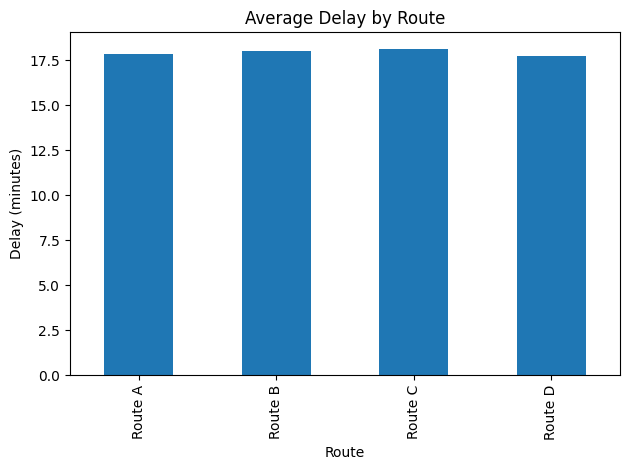

In [4]:
print("Dataset shape:", df.shape)
display(df.describe(include="all"))

df.groupby("route")["delay_minutes"].mean().plot(
    kind="bar",
    title="Average Delay by Route",
    ylabel="Delay (minutes)",
    xlabel="Route"
)

plt.tight_layout()
plt.show()

In [5]:
X = df.drop(columns=["delay_minutes"])
y = df["delay_minutes"]

categorical = ["route", "traffic_level", "weather"]
numeric = [
    "hour",
    "passenger_count",
    "scheduled_travel_minutes"
]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", "passthrough", numeric)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R² score:", r2_score(y_test, predictions))

MAE: 3.5849667261904767
RMSE: 4.560013560582578
R² score: 0.778157471723989


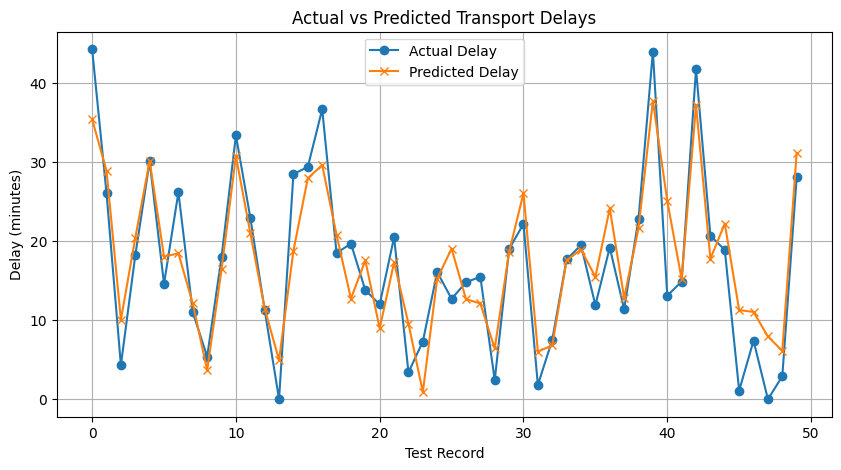

,Actual Delay,Predicted Delay
0,44.3,35.423
1,26.1,28.933
2,4.3,10.048
3,18.2,20.402
4,30.1,30.175
5,14.6,18.048
6,26.2,18.455
7,11.0,12.121
8,5.4,3.673
9,18.0,16.421


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Actual Delay": y_test,
    "Predicted Delay": predictions
})

results = results.reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(
    results.index[:50],
    results["Actual Delay"][:50],
    label="Actual Delay",
    marker="o"
)
plt.plot(
    results.index[:50],
    results["Predicted Delay"][:50],
    label="Predicted Delay",
    marker="x"
)

plt.title("Actual vs Predicted Transport Delays")
plt.xlabel("Test Record")
plt.ylabel("Delay (minutes)")
plt.legend()
plt.grid(True)
plt.show()

display(results.head(10))

In [7]:
# Predict delay for a hypothetical journey

new_journey = pd.DataFrame([{
    "route": "Route A",
    "hour": 18,
    "passenger_count": 65,
    "traffic_level": "High",
    "weather": "Rainy",
    "scheduled_travel_minutes": 45
}])

predicted_delay = model.predict(new_journey)[0]

print("PUBLIC TRANSPORT DELAY PREDICTION")
print("---------------------------------")
print("Route:", new_journey.loc[0, "route"])
print("Departure hour:", new_journey.loc[0, "hour"], ":00")
print("Traffic:", new_journey.loc[0, "traffic_level"])
print("Weather:", new_journey.loc[0, "weather"])
print("Scheduled travel time:",
      new_journey.loc[0, "scheduled_travel_minutes"], "minutes")
print("Predicted delay:", round(predicted_delay, 2), "minutes")
print("Estimated total journey time:",
      round(45 + predicted_delay, 2), "minutes")

PUBLIC TRANSPORT DELAY PREDICTION
---------------------------------
Route: Route A
Departure hour: 18 :00
Traffic: High
Weather: Rainy
Scheduled travel time: 45 minutes
Predicted delay: 38.09 minutes
Estimated total journey time: 83.09 minutes


In [8]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION")
print("----------------")
print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R² Score: {r2:.3f}")

MODEL EVALUATION
----------------
MAE:  3.58 minutes
RMSE: 4.56 minutes
R² Score: 0.778


AVERAGE DELAY BY ROUTE
route
Route C    18.13
Route B    18.02
Route A    17.83
Route D    17.72
Name: delay_minutes, dtype: float64


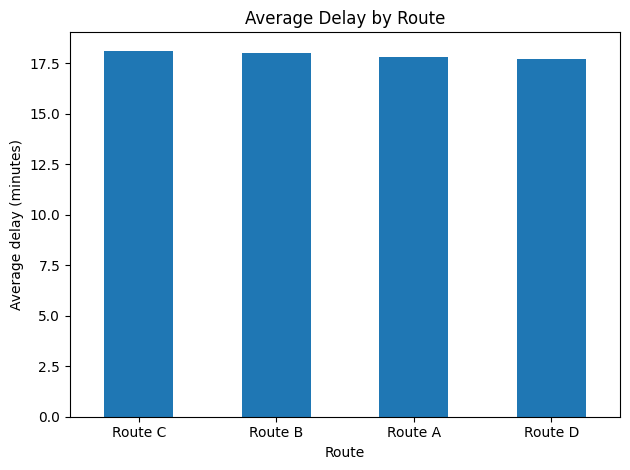


AVERAGE DELAY BY HOUR
hour
5     14.21
6     14.30
7     21.09
8     23.26
9     20.91
10    21.37
11    15.51
12    15.25
13    15.05
14    14.95
15    14.64
16    15.68
17    23.46
18    21.23
19    21.50
20    23.09
21    13.65
22    15.06
23    15.23
Name: delay_minutes, dtype: float64


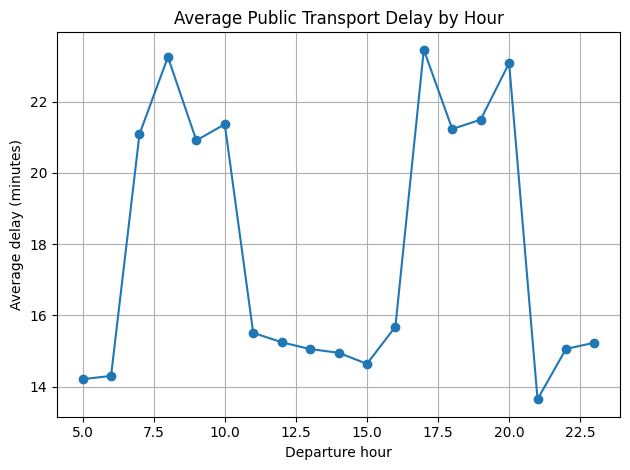


ROUTE WITH HIGHEST AVERAGE DELAY
Route: Route C
Average delay: 18.13 minutes


In [9]:

# 1. Average delay by route
route_analysis = (
    df.groupby("route")["delay_minutes"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE DELAY BY ROUTE")
print(route_analysis.round(2))

route_analysis.plot(kind="bar", title="Average Delay by Route")
plt.ylabel("Average delay (minutes)")
plt.xlabel("Route")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Average delay by departure hour
hour_analysis = df.groupby("hour")["delay_minutes"].mean()

print("\nAVERAGE DELAY BY HOUR")
print(hour_analysis.round(2))

hour_analysis.plot(
    kind="line",
    marker="o",
    title="Average Public Transport Delay by Hour"
)
plt.ylabel("Average delay (minutes)")
plt.xlabel("Departure hour")
plt.grid(True)
plt.tight_layout()
plt.show()


# 3. Identify the route with the highest average delay
worst_route = route_analysis.idxmax()
worst_delay = route_analysis.max()

print("\nROUTE WITH HIGHEST AVERAGE DELAY")
print("Route:", worst_route)
print("Average delay:", round(worst_delay, 2), "minutes")


In [10]:

import gradio as gr
import pandas as pd

def predict_delay(route, hour, passengers, traffic, weather, scheduled_time):
    journey = pd.DataFrame([{
        "route": route,
        "hour": int(hour),
        "passenger_count": int(passengers),
        "traffic_level": traffic,
        "weather": weather,
        "scheduled_travel_minutes": int(scheduled_time)
    }])

    delay = float(model.predict(journey)[0])

    return (
        f"Route: {route}\n"
        f"Departure: {int(hour):02d}:00\n"
        f"Predicted delay: {delay:.2f} minutes\n"
        f"Estimated total journey time: "
        f"{int(scheduled_time) + delay:.2f} minutes"
    )

demo = gr.Interface(
    fn=predict_delay,
    inputs=[
        gr.Dropdown(
            ["Route A", "Route B", "Route C", "Route D"],
            label="Route",
            value="Route A"
        ),
        gr.Slider(5, 23, value=18, step=1, label="Departure hour"),
        gr.Slider(5, 100, value=65, step=1, label="Passenger count"),
        gr.Dropdown(
            ["Low", "Medium", "High"],
            label="Traffic level",
            value="High"
        ),
        gr.Dropdown(
            ["Clear", "Rainy", "Cloudy"],
            label="Weather",
            value="Rainy"
        ),
        gr.Slider(
            15, 90, value=45, step=1,
            label="Scheduled travel time (minutes)"
        )
    ],
    outputs=gr.Textbox(label="Prediction", lines=5),
    title="Public Transport Delay Analytics",
    description=(
        "Explore estimated public transport delays using "
        "a machine-learning model trained on simulated data."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://038a929dfc9423f630.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

# Calculate dashboard KPIs
average_delay = df["delay_minutes"].mean()
maximum_delay = df["delay_minutes"].max()
total_journeys = len(df)

route_summary = (
    df.groupby("route", as_index=False)["delay_minutes"]
    .mean()
    .rename(columns={"delay_minutes": "average_delay"})
    .sort_values("average_delay", ascending=False)
)

worst_route = route_summary.iloc[0]["route"]
worst_route_delay = route_summary.iloc[0]["average_delay"]


def dashboard_summary():
    summary = f"""
PUBLIC TRANSPORT DELAY ANALYTICS

Total simulated journeys: {total_journeys}
Overall average delay: {average_delay:.2f} minutes
Maximum observed delay: {maximum_delay:.2f} minutes
Highest-average-delay route: {worst_route}
Average delay on that route: {worst_route_delay:.2f} minutes

Note: These are statistics from simulated data,
not live public transport measurements.
"""
    return summary


def route_chart():
    fig, ax = plt.subplots()
    ax.bar(route_summary["route"], route_summary["average_delay"])
    ax.set_title("Average Delay by Route")
    ax.set_xlabel("Route")
    ax.set_ylabel("Average Delay (minutes)")
    fig.tight_layout()
    return fig


with gr.Blocks(title="Transport Analytics Dashboard") as analytics_app:
    gr.Markdown("# Public Transport Delay Analytics")
    gr.Markdown("### Dataset Overview")

    gr.Textbox(
        value=dashboard_summary(),
        label="Key Performance Indicators",
        lines=9,
        interactive=False
    )

    gr.Plot(value=route_chart(), label="Route Comparison")

analytics_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0abffc6730f0895f81.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
